In [21]:
# Importer les packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [22]:
# Supprimer les warning
import warnings
warnings.filterwarnings("ignore")

### <font color = 'teal'>Importer et Lire les données<font>

In [23]:
# importer les données (non compris)
df = pd.read_csv('/content/Telephone_data.csv')
df.head()

,prix,adresse,marque,dim_ecr,ram,stockage,etat
0,580000,Guediawaye,iPhone,6.0,8,128,D'occasion
1,250000,Mermoz,iPhone,6.0,4,128,D'occasion
2,80000,Médina,iPhone,5.0,5,128,D'occasion
3,290000,Plateau,Samsung,6.0,8,256,D'occasion
4,250000,Mermoz,Samsung,6.0,8,256,D'occasion


In [24]:
# dimension des données
df.shape

(3253, 7)

In [25]:
# infos des données
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3253 entries, 0 to 3252
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   prix      3253 non-null   int64  
 1   adresse   3253 non-null   object 
 2   marque    3253 non-null   object 
 3   dim_ecr   3253 non-null   float64
 4   ram       3253 non-null   int64  
 5   stockage  3253 non-null   int64  
 6   etat      3253 non-null   object 
dtypes: float64(1), int64(3), object(3)
memory usage: 178.0+ KB


### <font color = 'teal'>Exploration et preparation des données<font>



###### <font color = 'bisque'> Selection des variables catégorielles et quantitatives

In [26]:
# selection les variables catégorielles
# selection les variables catégorielles
cat= df.select_dtypes(exclude = 'number')
cat.head()

,adresse,marque,etat
0,Guediawaye,iPhone,D'occasion
1,Mermoz,iPhone,D'occasion
2,Médina,iPhone,D'occasion
3,Plateau,Samsung,D'occasion
4,Mermoz,Samsung,D'occasion


In [27]:
# selection des variables quantitatives
# selection des variables quantitatives
quant_data = df.select_dtypes(include = 'number')
quant_data.head()

,prix,dim_ecr,ram,stockage
0,580000,6.0,8,128
1,250000,6.0,4,128
2,80000,5.0,5,128
3,290000,6.0,8,256
4,250000,6.0,8,256


###### <font color = 'bisque'> Exploration des variables catégorielles

In [28]:
# statistique descriptive des variables catégorielles
cat.describe().T

,count,unique,top,freq
adresse,3253,43,Plateau,415
marque,3253,28,iPhone,1571
etat,3253,4,Réconditionné,1053


In [29]:
# fonction de countplot
import plotly.express as px
def countplot_func(col):
  val = df[col].value_counts()
  fig = px.bar(x=val.index, y=val.values, color = val.index.astype(str), text_auto=True)
  fig.show()

In [30]:
# Diagrammes en barre des variables catégorielles
for col in cat_data.columns:
  countplot_func(col)

###### <font color = 'bisque'> Exploration des variables quantitatives

In [31]:
# décrire les variables quantitatives
quant_data.describe().T

,count,mean,std,min,25%,50%,75%,max
prix,3253.0,360830.307101,215801.003089,1.0,237043.0,362043.0,462044.0,3335000.0
dim_ecr,3253.0,6.510913,3.466092,0.0,6.0,6.0,7.0,75.0
ram,3253.0,16.377498,20.291301,1.0,11.0,12.0,14.0,512.0
stockage,3253.0,193.514294,169.625904,1.0,128.0,158.0,256.0,5120.0


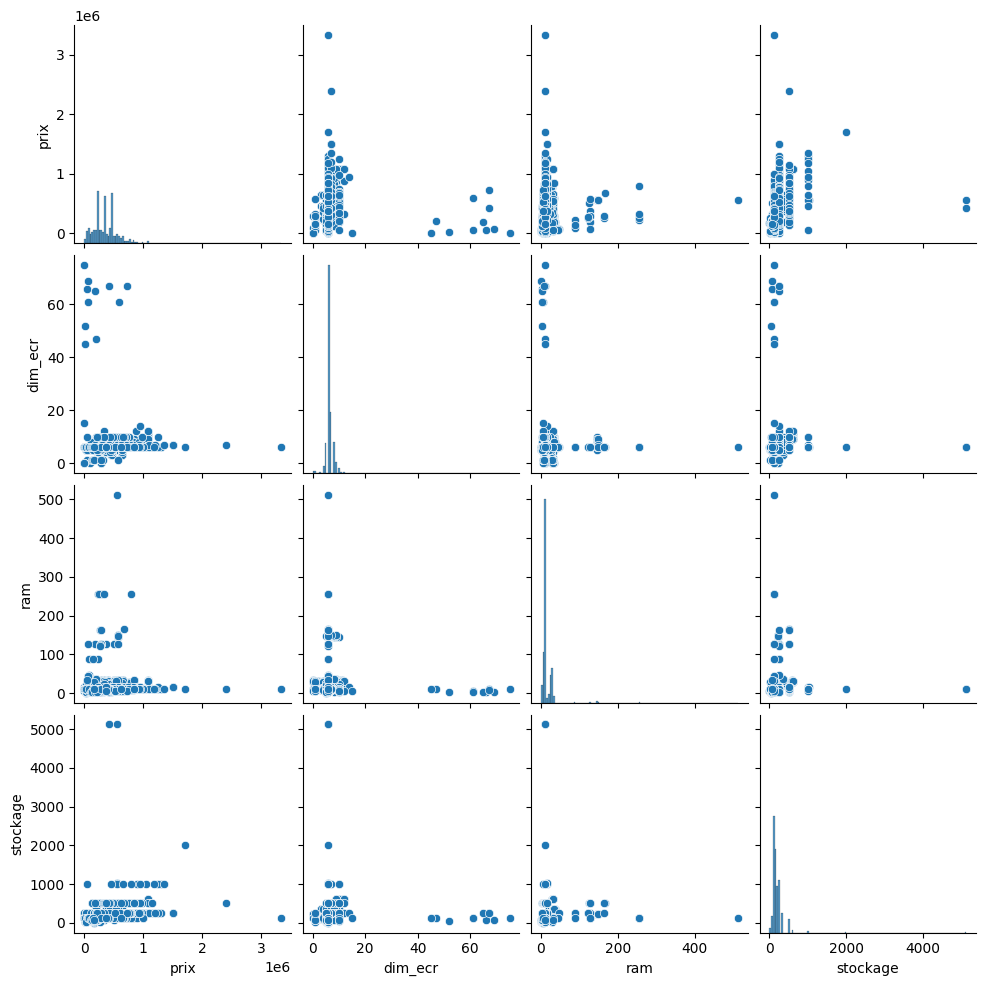

In [32]:
# pairplot des variables quantitatives
sns.pairplot(quant_data)
plt.show()

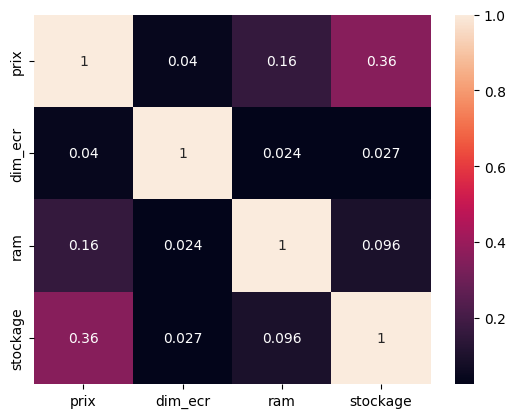

In [33]:
#matrice de correlation
sns.heatmap(quant_data.corr(), annot = True)
plt.show()

In [34]:
# fonction de visualisation des boxplots
def boxplot_func(col):
  plt.figure(figsize=(25,3))
  sns.boxplot(x=df[col])
  plt.show()

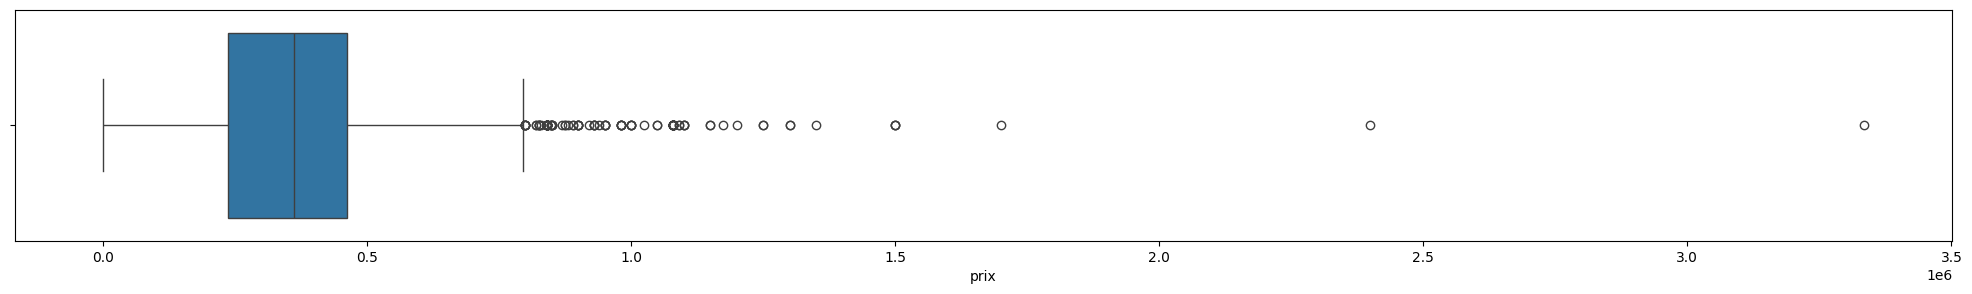

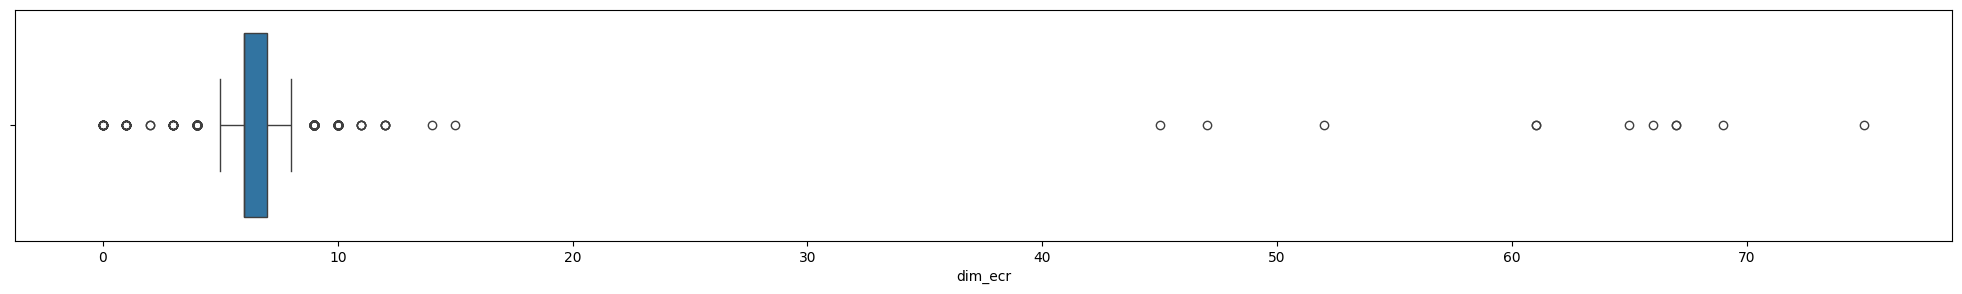

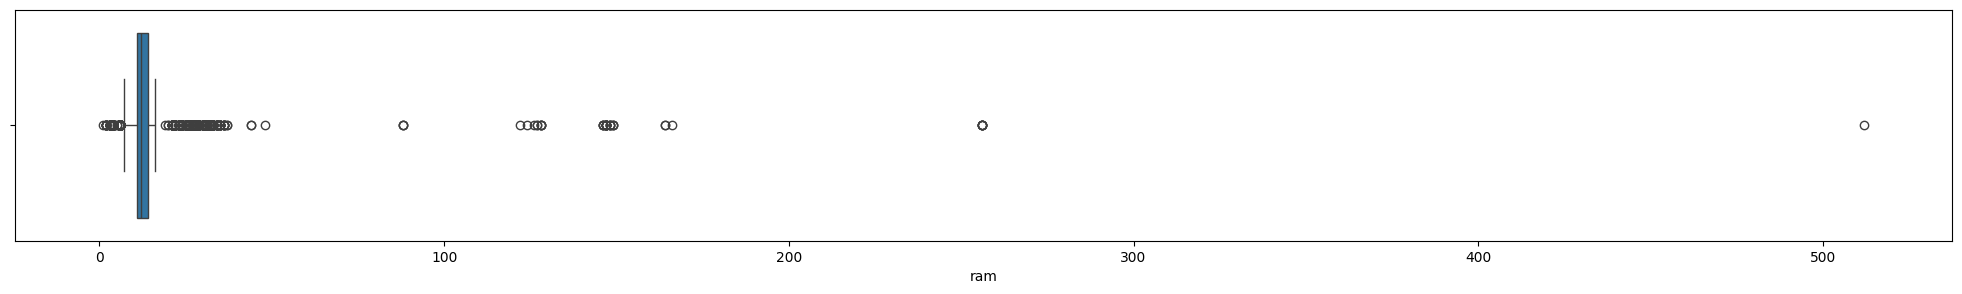

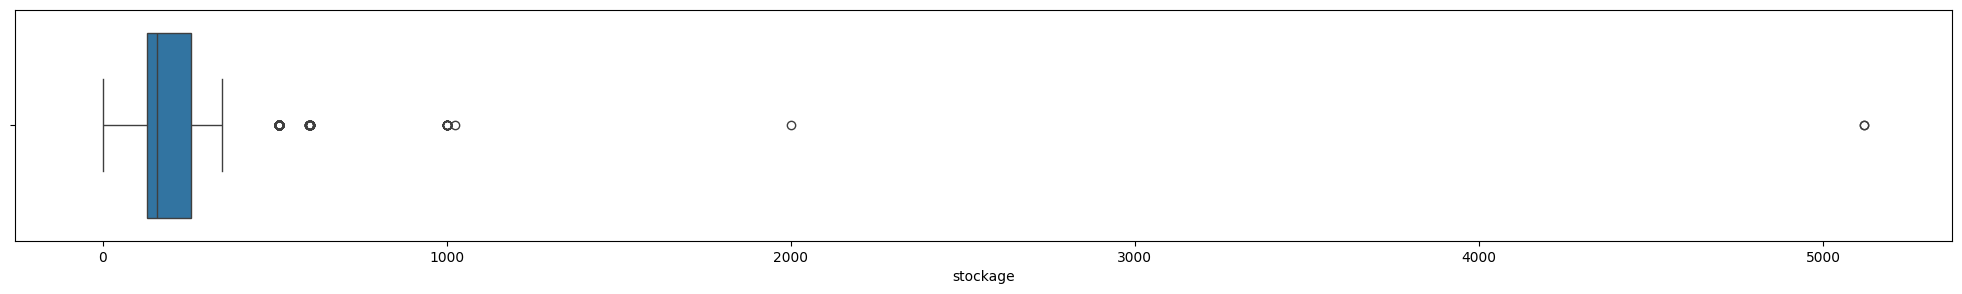

In [35]:
# boxplots des variables quantitatives
for col in quant_data.columns:
  boxplot_func(col)

###### <font color = 'bisque'> Preparation des données

In [37]:
import os
# Enregistrer les valeurs uniques des variables catégorielles dans un objet joblib
uniques = []
for col in cat.columns:
  uniques.append(np.unique(df[col]).tolist())
# Créer le dossier s'il n'existe pas
os.makedirs('/content/model', exist_ok=True)
# sauvegarde
import joblib as jb
jb.dump(uniques, '/content/model/uniques.joblib')

['/content/model/uniques.joblib']

In [38]:
# Encoder les variables catégorielles
from sklearn.preprocessing import LabelEncoder
# Créer différents encodeurs pour les variables catégorielles
encoders = []
for i in range(len(cat.columns)):
  encoder = LabelEncoder()
  encoder.fit(df[cat.columns[i]]) # le modèle prend le temps de reconnaitre les classes
  df[cat.columns[i]] = encoder.transform(df[cat.columns[i]]) # encoder les valeurs
  # rajouter l'encoder sur la liste encoders
  encoders.append(encoder)

In [39]:
import joblib as jb
# sauvegarde les encodeurs
jb.dump(encoders, '/content/model/encoders.joblib')

['/content/model/encoders.joblib']

In [40]:
from sklearn.impute import KNNImputer
# fonction d'imputation des valeurs aberrantes
def impute_func(df, col, n_neighbors=5):
    # 2. Détection des outliers (Méthode IQR)
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    min_value = Q1 - 1.5 * IQR
    max_value = Q3 + 1.5 * IQR

    # Les valeurs hors bornes deviennent des valeurs manquantes pour le KNNImputer
    df.loc[(df[col] < min_value) | (df[col] > max_value), col] = np.nan
    # n_neighbors : nombre de voisins pour calculer la moyenne de remplacement
    imputer = KNNImputer(n_neighbors=n_neighbors)
    df[:] = imputer.fit_transform(df)

In [41]:
# imputation des valeurs extrêmes
for col in quant_data.columns:
  impute_func(df,col)

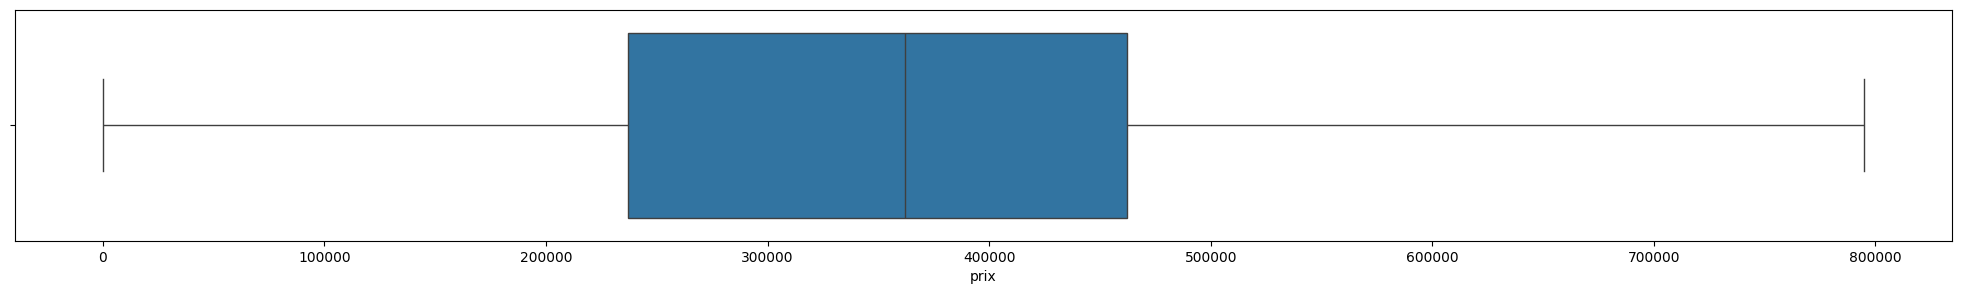

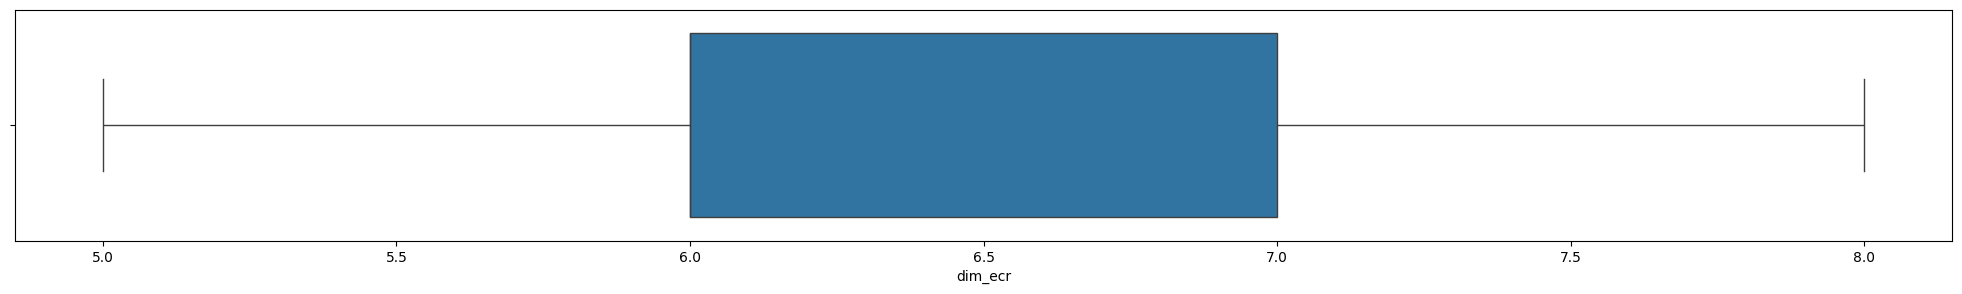

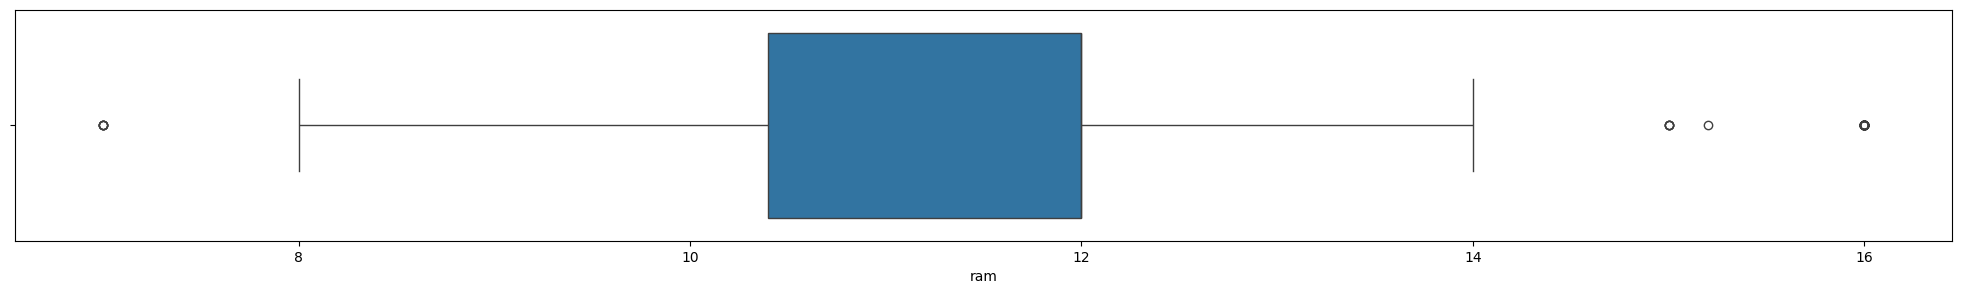

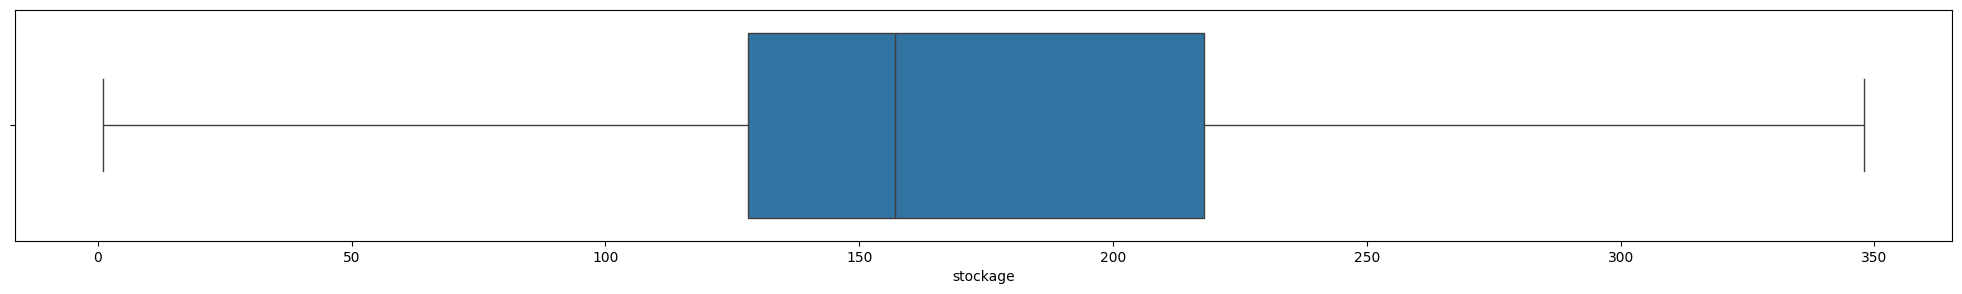

In [42]:
# Réafficher les boxplots
for col in quant_data.columns:
  boxplot_func(col)

In [43]:
# Fractionner les données en variables prédicteurs (x) et variable cibel(y)
x = df.drop('etat', axis = 1).values
y = df.etat.values
x[:5], y[:5]

(array([[5.80e+05, 1.30e+01, 2.70e+01, 6.00e+00, 8.00e+00, 1.28e+02],
        [2.50e+05, 2.20e+01, 2.70e+01, 6.00e+00, 1.12e+01, 1.28e+02],
        [8.00e+04, 2.30e+01, 2.70e+01, 5.00e+00, 1.04e+01, 1.28e+02],
        [2.90e+05, 3.20e+01, 1.90e+01, 6.00e+00, 8.00e+00, 2.56e+02],
        [2.50e+05, 2.20e+01, 1.90e+01, 6.00e+00, 8.00e+00, 2.56e+02]]),
 array([0, 0, 0, 0, 0]))

In [44]:
# normaliser les données
# importer RobustScaler
from sklearn.preprocessing import RobustScaler
# Normaliser x
scaler = RobustScaler()
scaler.fit(x)
x = scaler.transform(x)
from sklearn.preprocessing import MinMaxScaler # Z = (X-Xmin)/(Xmax - Xmin)
scaler = MinMaxScaler()
x = scaler.fit_transform(x)
x[:5]

array([[0.72955941, 0.30952381, 1.        , 0.33333333, 0.11111111,
        0.36599424],
       [0.31446455, 0.52380952, 1.        , 0.33333333, 0.46666667,
        0.36599424],
       [0.1006278 , 0.54761905, 1.        , 0.        , 0.37777778,
        0.36599424],
       [0.36477908, 0.76190476, 0.7037037 , 0.33333333, 0.11111111,
        0.73487032],
       [0.31446455, 0.52380952, 0.7037037 , 0.33333333, 0.11111111,
        0.73487032]])

In [45]:
# splitter les données en train, val et test
# train (80%), val(10%) et test(10%)
#train : données d'entrainement, val: données utiliser pour évaluer chaque et test: données pour tester le modèle le plus performant
from sklearn.model_selection import train_test_split
x_train, x_val_test, y_train, y_val_test = train_test_split(x, y, train_size = 0.8, random_state = 42)# 80% -- 20%
x_val, x_test, y_val, y_test = train_test_split(x_val_test, y_val_test, train_size = 0.5, random_state = 42)# 80% -- 20%

### <font color = 'teal'>Logistic Regression<font>

###### <font color = 'bisque'> Recherche des paramètre optimaux

In [46]:
from sklearn.model_selection import GridSearchCV
# Recherche des paramètres optimaux pour la logistic regression
from sklearn.linear_model import LogisticRegression
# dictionnaire params
params={"C":np.logspace(-3,3,10),"penalty": ['l1','l2']}
# instantier le modèle Logistic regression
lg=LogisticRegression()
# instantier le modèle gridsearch
grid=GridSearchCV(lg,params,cv=5)
# lancer la recherche
grid.fit(x_train,y_train)

GridSearchCV(cv=5, estimator=LogisticRegression(),
             param_grid={'C': array([1.00000000e-03, 4.64158883e-03, 2.15443469e-02, 1.00000000e-01,
       4.64158883e-01, 2.15443469e+00, 1.00000000e+01, 4.64158883e+01,
       2.15443469e+02, 1.00000000e+03]),
                         'penalty': ['l1', 'l2']})

In [47]:
# Afficher les paramètres optimaux
grid.best_params_

{'C': np.float64(0.46415888336127775), 'penalty': 'l2'}

###### <font color = 'bisque'> Entrainement du modèle

In [48]:
# Entrainer la logistic regression en utilisant les paramètres optimaux
lg_model = LogisticRegression( C = 0.46415888336127775, penalty =  'l2')
lg_model.fit(x_train,y_train)

LogisticRegression(C=0.46415888336127775)

###### <font color ='bisque'>Evaluation du modèle

In [49]:
# fonction d'évaluation
from sklearn.metrics import f1_score, accuracy_score
def evaluation(model):
  y_pred = model.predict(x_val)
  acc = accuracy_score(y_val, y_pred)
  f1 = f1_score(y_val, y_pred, average='micro')
  return acc, f1

In [50]:
# Accuracy et F1 score du modèle sur les données de validation
acc_lg, f1_lg = evaluation(lg_model)
print(f"Accuracy : {acc_lg} --- F1 score : {f1_lg}")

Accuracy : 0.68 --- F1 score : 0.68


In [51]:
# Importer ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
# y_pred:  prédictions du modèle sur les données validation
def CM_visualisation(model_objet):

    y_pred = model_objet.predict(x_val)
    # Confusion matrix
    cnf_matr = confusion_matrix(y_val, y_pred, labels=[0,1,2,3])

    # Utiliser ConfusionMatrixDisplay pour visualiser la matrice de confusion
    disp = ConfusionMatrixDisplay(confusion_matrix=cnf_matr,
                                  display_labels=['Occasion','Neuf', 'Reconditionné','Venant'])
    disp.plot() # Afficher la matrice de confusion
    plt.title('Matrice de confusion') # Définir le titre
    plt.show() # Afficher la figure

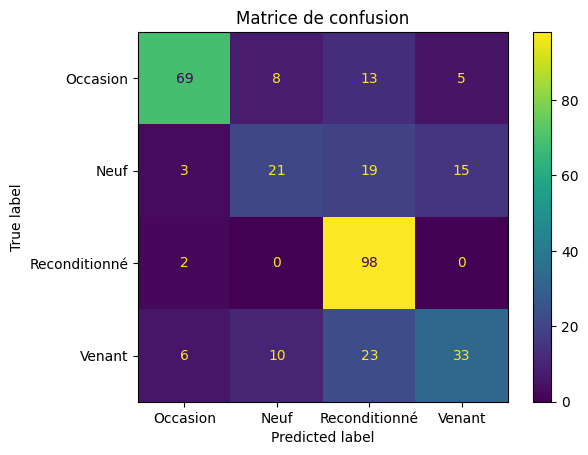

In [52]:
# Matrice de confusion
CM_visualisation(lg_model)

### <font color = 'teal'>Decision Tree<font>

###### <font color = 'bisque'> Recherche des paramètre optimaux

In [53]:
# Recherche des paramètres optimaux pour le Decision Tree
from sklearn.tree import DecisionTreeClassifier
# dictionnaire des params
param__ = {'criterion':['gini','entropy'],'max_depth':np.arange(3,15)}
# instantier le modèle Decision Tree
dt = DecisionTreeClassifier()
# instantier le modèle gridsearch
grid__ = GridSearchCV(dt, param__, cv = 5)
# entrainer le modèle
grid__.fit(x_train, y_train)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(),
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': array([ 3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14])})

In [54]:
# afficher les paramètres optimaux
grid__.best_params_

{'criterion': 'gini', 'max_depth': np.int64(13)}

###### <font color = 'bisque'> Entrainement du modèle

In [55]:
# Entrainer le modèle en utilisant les paramètres optimaux
dt_model = DecisionTreeClassifier(criterion = 'gini', max_depth = 13)
dt_model.fit(x_train, y_train)

DecisionTreeClassifier(max_depth=13)

###### <font color ='bisque'>Evaluation du modèle<font>

In [56]:
# Accuracy et F1 score du modèle sur les données de validation
acc_dt, f1_dt = evaluation(dt_model)
print(f"Accuracy : {acc_dt} --- F1 score : {f1_dt}")

Accuracy : 0.8092307692307692 --- F1 score : 0.8092307692307692


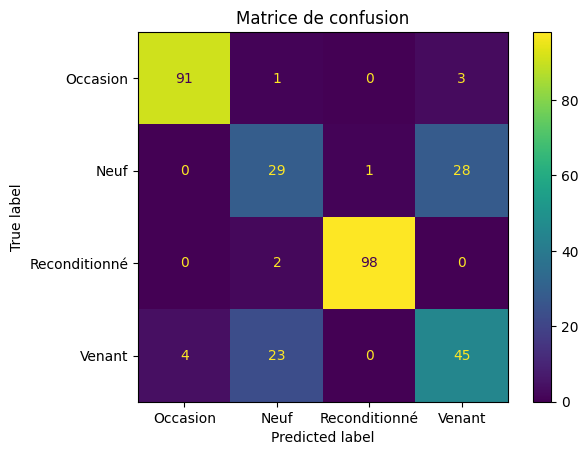

In [57]:
# Matrice de confusion
CM_visualisation(dt_model)

### <font color = 'teal'>Random Forest<font>

In [58]:
# Recherche des paramètres optimaux pour le Random Forest
from sklearn.ensemble import RandomForestClassifier
# dictionnaire des  params
params = param_grid = {
    'n_estimators': list(np.arange(10,100,10)),
    'max_depth' : list(np.arange(3,15)),
    'criterion' :['gini', 'entropy']
}
# instantier le modèle Random Forest
rf = RandomForestClassifier()
# instantier le modèle gridsearch
grid = GridSearchCV(estimator=rf, param_grid=params, cv= 5)
# entrainer le modèle
grid.fit(x_train, y_train)

GridSearchCV(cv=5, estimator=RandomForestClassifier(),
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [np.int64(3), np.int64(4), np.int64(5),
                                       np.int64(6), np.int64(7), np.int64(8),
                                       np.int64(9), np.int64(10), np.int64(11),
                                       np.int64(12), np.int64(13),
                                       np.int64(14)],
                         'n_estimators': [np.int64(10), np.int64(20),
                                          np.int64(30), np.int64(40),
                                          np.int64(50), np.int64(60),
                                          np.int64(70), np.int64(80),
                                          np.int64(90)]})

In [59]:
# Afficher les paramètres optimaux
grid.best_params_

{'criterion': 'gini', 'max_depth': np.int64(11), 'n_estimators': np.int64(30)}

In [60]:
# Entrainer Random Forest en utilisant les paramètres optimaux
rf_model = RandomForestClassifier(criterion= 'gini', max_depth=9,  n_estimators = 30)
rf_model.fit(x_train, y_train)

RandomForestClassifier(max_depth=9, n_estimators=30)

##### <font color ='bisque'>Evaluation du Random Forest<font>

In [61]:
# Accuracy et F1 score du modèle sur les données de validation
acc_rf, f1_rf = evaluation(rf_model)
print(f"Accuracy : {acc_rf} --- F1 score : {f1_rf}")

Accuracy : 0.8707692307692307 --- F1 score : 0.8707692307692307


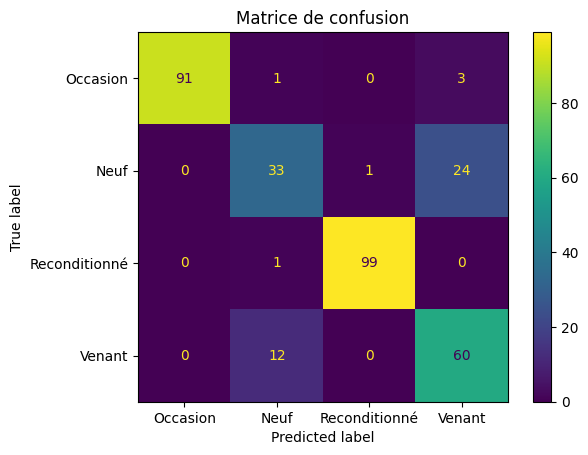

In [62]:
# Matrice de confusion
CM_visualisation(rf_model)

In [63]:
#diagrammes des performances
list_names = ['LG', 'DT', 'RF']
list_acc = [acc_lg, acc_dt, acc_rf]
list_f1 = [f1_lg, f1_dt,f1_rf]
list_final = [list_acc, list_f1]
for i in range(2):
  fig = px.bar(y=list_names, x= list_final[i], color = list_names, text_auto = True)
  fig.show()

In [64]:
# télécharger le modèle le plus performant
jb.dump(rf_model, '/content/model/rf_model.joblib')

['/content/model/rf_model.joblib']

### <font color ='bisque'>Tester le modèle le plus performant<font>

In [65]:
# echantillons
x_test_10 = x_test[:10]
y_test_10 = y_test[:10]
# prédictions
y_pred_10 = rf_model.predict(x_test_10)
classnames = ['occasion', 'neuf', 'reconditionné', 'venant']
for i in range(10):
  print(f"Prédiction {str(i +1)} : {classnames[y_pred_10[i]]}  -- {classnames[y_test_10[i]]}")

Prédiction 1 : venant  -- venant
Prédiction 2 : neuf  -- neuf
Prédiction 3 : occasion  -- occasion
Prédiction 4 : occasion  -- occasion
Prédiction 5 : occasion  -- occasion
Prédiction 6 : reconditionné  -- reconditionné
Prédiction 7 : venant  -- venant
Prédiction 8 : neuf  -- venant
Prédiction 9 : reconditionné  -- reconditionné
Prédiction 10 : venant  -- venant
